In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install rasterio
!pip install patchify

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.2/22.2 MB 52.7 MB/s eta 0:00:00


In [ ]:
import rasterio as rst
from patchify import patchify ,unpatchify
import os
import numpy as np

In [ ]:
dataset = rst.open('/content/drive/MyDrive/timeseries/2015/s1_1vv_2015.tif')
print(dataset)

<open DatasetReader name='/content/drive/MyDrive/timeseries/2015/s1_1vv_2015.tif' mode='r'>


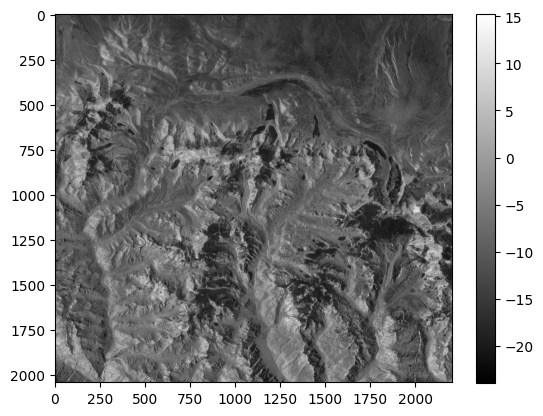

In [ ]:
dataset_np = dataset.read()
im_1=dataset_np.shape
im_1
import matplotlib.pyplot as plt
imshow= plt.imshow(dataset_np[0,:,:], cmap='gray')
plt.colorbar()

In [ ]:
im_1

(1, 2041, 2202)

In [ ]:
for i in range(4):
  !mkdir /content/drive/MyDrive/rashid_trials/time/2024/geotiff/im_{1+i}



# Reconstructing a Complete NumPy Array from Image Patches

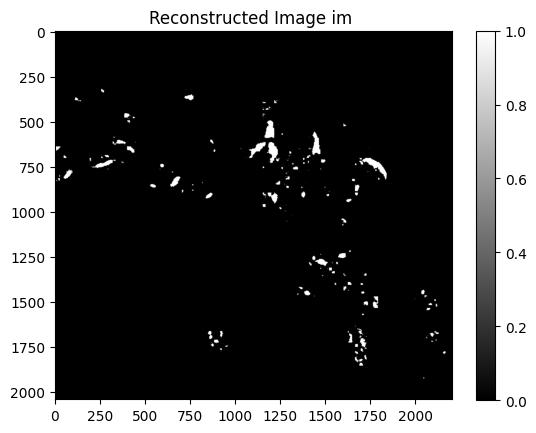

In [ ]:
import numpy as np
import os
import matplotlib.pyplot as plt

# Path to predicted patches folder
predicted_patches_folder = '/content/drive/MyDrive/rashid_trials/time/2024/predictions/im_4'

# Define the original image shape manually
original_image_shape = (2041,2202)
patch_size = 64
blank_patch = np.zeros((patch_size, patch_size))

# Calculate grid dimensions
grid_rows = original_image_shape[0] // patch_size
grid_cols = original_image_shape[1] // patch_size

# Initialize the blank image for reconstruction
reconstructed_image_im = np.zeros(original_image_shape)



# Process each grid position
for row_idx in range(grid_rows):
    for col_idx in range(grid_cols):
        # Construct the expected patch filename
        patch_filename = f'patch_{row_idx}_{col_idx}.npy'
        patch_file = os.path.join(predicted_patches_folder, patch_filename)

        # Load the patch if it exists, otherwise use the blank patch
        if os.path.exists(patch_file):
            patch = np.load(patch_file)
        else:
            patch = blank_patch

        # Place the patch into the reconstructed image
        reconstructed_image_im[
            row_idx * patch_size: (row_idx + 1) * patch_size,
            col_idx * patch_size: (col_idx + 1) * patch_size,

        ] = patch

# Save and visualize the reconstructed image
np.save('/content/drive/MyDrive/rashid_trials/time/2024/recon/im_4', reconstructed_image_im)

plt.imshow(reconstructed_image_im, cmap = 'gray')
plt.colorbar()
plt.title('Reconstructed Image im ')
plt.show()

# Converting a NumPy Array to GeoTIFF with Geospatial Metadata

In [ ]:
import numpy as np
import rasterio
from rasterio.transform import from_origin

# Path to files
original_raster_path = '/content/drive/MyDrive/timeseries/2024/s1_1vv_2024.tif'
output_raster_path = '/content/drive/MyDrive/rashid_trials/time/2024/geotiff/im_4'
reconstructed_image = np.load('/content/drive/MyDrive/rashid_trials/time/2024/recon/im_4.npy')

# Read the original raster for geographic information
with rasterio.open(original_raster_path) as src:
    transform = src.transform
    crs = src.crs
    dtype = src.dtypes[0]  # Use the same data type as the original raster

# Ensure the reconstructed image has the correct dimensions
height, width = reconstructed_image.shape

# Write the reconstructed image as a GeoTIFF
with rasterio.open(
    output_raster_path,
    'w',
    driver='GTiff',
    height=height,
    width=width,
    count=1,
    dtype=dtype,
    crs=crs,
    transform=transform,
) as dst:
    dst.write(reconstructed_image, 1)

print(f"Reconstructed raster saved to {output_raster_path}")

Reconstructed raster saved to /content/drive/MyDrive/rashid_trials/time/2024/geotiff/im_4


# Verifying Saved Data

<open DatasetReader name='/content/drive/MyDrive/rashid_trials/time/2024/geotiff/im_4' mode='r'>
(1, 2041, 2202)


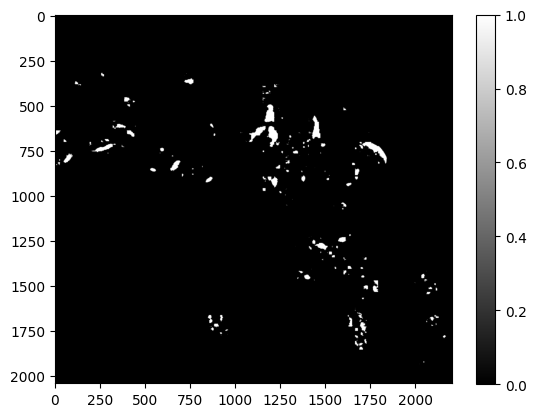

In [ ]:
chk= rst.open('/content/drive/MyDrive/rashid_trials/time/2024/geotiff/im_4')
print(chk)
chk_np = chk.read()
print(chk_np.shape)
plt.imshow(chk_np[0,:,:], cmap='gray')
plt.colorbar()